# Engenharia de atributos e modelagem preditiva

**Notebook 04 de 04** · Entrada: `dados/diabetes_tratado.parquet` (gerado no notebook 01)

**Objetivo:** treinar e comparar modelos de classificação para prever `Diabetes` a partir dos demais indicadores de saúde. Na fonte original, `Sim` agrupa pessoas com **pré-diabetes ou diabetes**.

**Critério de avaliação:** o uso pensado é de **triagem de risco**. Nesse cenário, um falso negativo (pessoa em risco que o modelo deixa passar) é mais grave que um falso positivo (pessoa saudável encaminhada para um exame). Por isso, além do ROC-AUC, damos atenção ao **Recall** e ajustamos o limiar de decisão.


## Importações

Todas as importações do notebook ficam concentradas nesta célula. O `sys.path.append` permite importar o pacote `src` a partir da pasta `notebooks/`. A `SEMENTE` fixa a aleatoriedade para que os resultados sejam reproduzíveis.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Os notebooks ficam em notebooks/. Adicionamos a raiz do projeto ao caminho de
# importação para que o pacote `src` seja encontrado.
sys.path.append(str(Path.cwd().parent))

from src.config import DADOS_TRATADOS, PASTA_IMAGENS
from src.preprocessamento import codificar_atributos

SEMENTE = 42  # fixa a aleatoriedade (divisão dos dados, florestas, validação cruzada)


## Carregando a base tratada

Lê o arquivo `.parquet` gerado no notebook 01, que preserva os tipos `category` e `int8`.


In [2]:
df_diabetes_tratado = pd.read_parquet(DADOS_TRATADOS)

df_diabetes_tratado.shape


(70692, 22)

## Engenharia de atributos

Os algoritmos de classificação exigem entradas numéricas, mas a base tratada tem colunas `category`. A função `codificar_atributos` (em `src/preprocessamento.py`) faz a conversão:

- **Alvo:** `Sim` vira 1 e `Não` vira 0.
- **Binárias:** viram 0 e 1 (`Sexo`: Feminino = 0, Masculino = 1).
- **Ordinais** (`SaudeGeral`, `FaixaIdade`, `Ensino`, `FaixaRenda`): viram o código da categoria, que respeita a ordem natural definida no notebook 01. Assim o modelo enxerga que "Ruim" está acima de "Boa", e não apenas que são categorias diferentes. Um *one-hot encoding* descartaria essa ordem e criaria dezenas de colunas.
- **Numéricas:** ficam como estão. O escalonamento (necessário só para a regressão logística) é feito dentro do pipeline do modelo, para ser aprendido apenas com os dados de treino.

Esse mapeamento é fixo e não aprende nada com os dados, então pode ser aplicado antes da separação treino/teste sem vazamento de dados.


In [3]:
X, y = codificar_atributos(df_diabetes_tratado)

display(X.head())

print(f"Atributos: {X.shape[1]} | Registros: {X.shape[0]}")
print(f"Proporção da classe positiva (Diabetes = Sim): {y.mean():.1%}")


,PressaoAlta,ColesterolAlto,ColesterolExame,IMC,Fumante,AVC,ProblemaCardiaco,AtividadeFisica,ComeFrutas,ComeLegumes,...,PlanoSaude,SemDinheiroConsultas,SaudeGeral,DiasProblemasMentais,DiasProblemasFisicos,DificuldadeAndar,Sexo,FaixaIdade,Ensino,FaixaRenda
0,1,0,1,26,0,0,0,1,0,1,...,1,0,2,5,30,0,1,3,5,7
1,1,1,1,26,1,1,0,0,1,0,...,1,0,2,0,0,0,1,11,5,7
2,0,0,1,26,0,0,0,1,1,1,...,1,0,0,0,10,0,1,12,5,7
3,1,1,1,28,1,0,0,1,1,1,...,1,0,2,0,3,0,1,10,5,7
4,0,0,1,29,1,0,0,1,1,1,...,1,0,1,0,0,0,0,7,4,7


Atributos: 21 | Registros: 70692
Proporção da classe positiva (Diabetes = Sim): 50.0%


## Separação em treino e teste

Reservamos 20% dos registros para o **teste final**, usado uma única vez, só para avaliar os modelos já escolhidos. A divisão é estratificada (`stratify=y`), para manter a proporção entre as classes nos dois conjuntos. Todas as decisões (escolha do modelo e do limiar) usam apenas o conjunto de treino.


In [4]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMENTE
)

print(f"Treino: {X_treino.shape[0]} registros | Teste: {X_teste.shape[0]} registros")


Treino: 56553 registros | Teste: 14139 registros


## Comparando modelos com validação cruzada

Comparamos três modelos de complexidade crescente:

- **Regressão Logística:** modelo linear e interpretável, usado como referência.
- **Random Forest:** conjunto de árvores de decisão, captura interações entre variáveis.
- **Gradient Boosting (`HistGradientBoostingClassifier`):** árvores treinadas em sequência, cada uma corrigindo os erros das anteriores. Costuma ter ótimo desempenho em dados tabulares.

Como a base é balanceada (50% de cada classe), um chute aleatório teria ROC-AUC de 0,50, e é esse o piso para comparação. A avaliação usa **validação cruzada estratificada com 5 partições** apenas nos dados de treino, e as métricas são as médias das 5 partições.


In [5]:
modelos = {
    "Regressão Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=SEMENTE
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=SEMENTE),
}

validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
metricas = ["roc_auc", "recall", "precision", "f1"]

resultados = {}
for nome, modelo in modelos.items():
    cv = cross_validate(modelo, X_treino, y_treino, cv=validacao, scoring=metricas, n_jobs=-1)
    resultados[nome] = {metrica: cv[f"test_{metrica}"].mean() for metrica in metricas}

resultados_cv = pd.DataFrame(resultados).T.round(3).sort_values("roc_auc", ascending=False)

resultados_cv


,roc_auc,recall,precision,f1
Gradient Boosting,0.830,0.798,0.731,0.763
Random Forest,0.827,0.794,0.730,0.761
Regressão Logística,0.825,0.768,0.739,0.753


O modelo com maior ROC-AUC na validação cruzada é escolhido para as próximas etapas. A escolha é feita no código, a partir da tabela acima. Repare que os três modelos ficam bem próximos: a diferença entre eles é pequena perto da diferença para o chute aleatório (ROC-AUC de 0,50).


In [6]:
melhor_nome = resultados_cv.index[0]
melhor_modelo = modelos[melhor_nome]

print(f"Modelo escolhido: {melhor_nome}")


Modelo escolhido: Gradient Boosting


## Avaliação no conjunto de teste

Treinamos os três modelos com todo o conjunto de treino e comparamos as curvas ROC no conjunto de teste, que nenhum modelo viu até aqui. A curva mostra a troca entre a taxa de verdadeiros positivos (Recall) e a de falsos positivos em todos os limiares possíveis. Quanto mais perto do canto superior esquerdo, melhor.


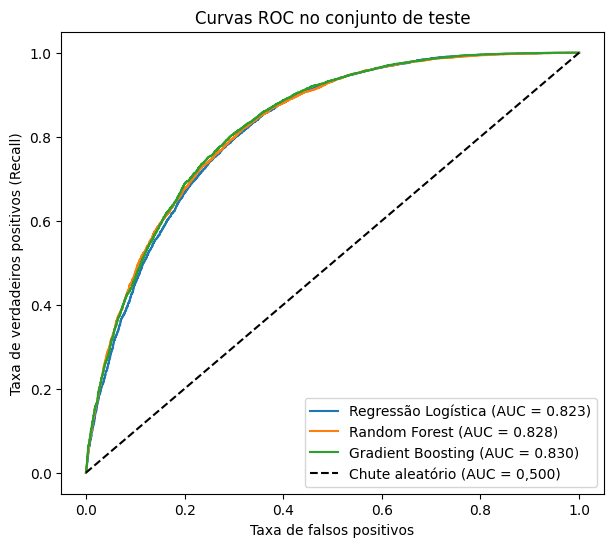

In [7]:
fig, ax = plt.subplots(figsize=(7, 6))

for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    probabilidades = modelo.predict_proba(X_teste)[:, 1]
    auc = roc_auc_score(y_teste, probabilidades)
    fpr, tpr, _ = roc_curve(y_teste, probabilidades)
    ax.plot(fpr, tpr, label=f"{nome} (AUC = {auc:.3f})")

ax.plot([0, 1], [0, 1], "k--", label="Chute aleatório (AUC = 0,500)")
ax.set_xlabel("Taxa de falsos positivos")
ax.set_ylabel("Taxa de verdadeiros positivos (Recall)")
ax.set_title("Curvas ROC no conjunto de teste")
ax.legend(loc="lower right")

fig.savefig(PASTA_IMAGENS / "curvas_roc.png", dpi=150, bbox_inches="tight")
plt.show()


## Ajustando o limiar de decisão

Por padrão, o modelo classifica como `Sim` quem tem probabilidade de pelo menos 0,50. Para uma triagem, podemos aceitar mais falsos positivos em troca de deixar menos casos passarem. O critério adotado é: **o maior limiar que ainda garante Recall de pelo menos 90%**. Quanto maior o limiar, maior a precisão, então esse é o ponto que perde menos precisão para atingir a meta. A meta de 90% é uma escolha de projeto e pode ser ajustada conforme o uso.

O limiar é escolhido com **previsões fora da amostra no conjunto de treino** (`cross_val_predict`): cada registro é previsto por um modelo que não o viu no treino. Assim o conjunto de teste continua intocado para a avaliação final.


Limiar escolhido: 0.352
No treino (fora da amostra): recall = 90.0%, precisão = 68.1%


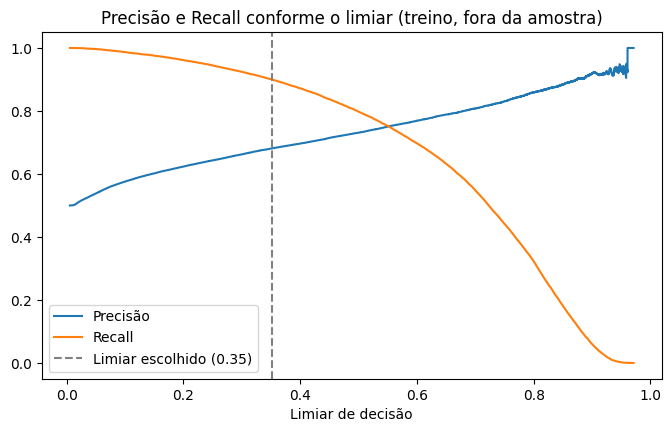

In [8]:
META_RECALL = 0.90

probabilidades_treino = cross_val_predict(
    melhor_modelo, X_treino, y_treino, cv=validacao, method="predict_proba", n_jobs=-1
)[:, 1]

precisao, recall, limiares = precision_recall_curve(y_treino, probabilidades_treino)

# precisao e recall têm um elemento a mais que limiares; [:-1] alinha os três.
# O recall cai conforme o limiar sobe: o último índice que cumpre a meta é o maior limiar possível.
indices_validos = np.where(recall[:-1] >= META_RECALL)[0]
indice = indices_validos[-1]
limiar_escolhido = limiares[indice]

print(f"Limiar escolhido: {limiar_escolhido:.3f}")
print(f"No treino (fora da amostra): recall = {recall[indice]:.1%}, precisão = {precisao[indice]:.1%}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(limiares, precisao[:-1], label="Precisão")
ax.plot(limiares, recall[:-1], label="Recall")
ax.axvline(limiar_escolhido, color="gray", linestyle="--", label=f"Limiar escolhido ({limiar_escolhido:.2f})")
ax.set_xlabel("Limiar de decisão")
ax.set_title("Precisão e Recall conforme o limiar (treino, fora da amostra)")
ax.legend()
plt.show()


Agora comparamos, no **conjunto de teste**, o limiar padrão (0,50) com o limiar ajustado.


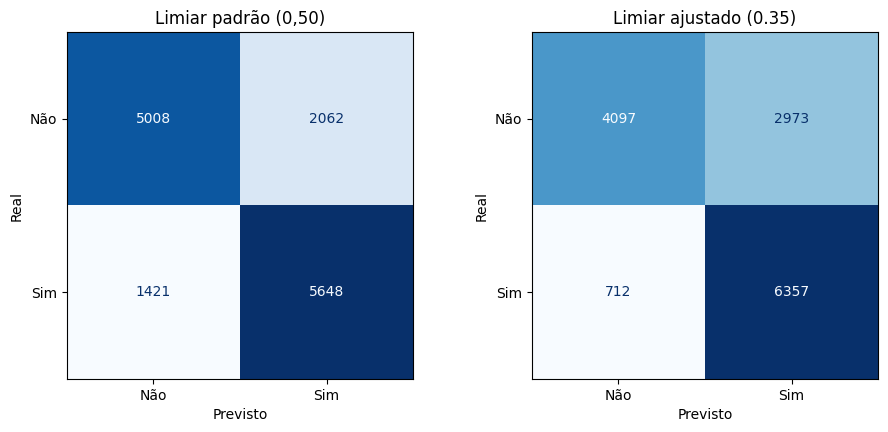

,"Limiar padrão (0,50)",Limiar ajustado (0.35)
Recall,0.799,0.899
Precisão,0.733,0.681
F1,0.764,0.775
Acurácia,0.754,0.739
ROC-AUC,0.830,0.830


In [9]:
probabilidades_teste = melhor_modelo.predict_proba(X_teste)[:, 1]

previsoes = {
    "Limiar padrão (0,50)": probabilidades_teste >= 0.5,
    f"Limiar ajustado ({limiar_escolhido:.2f})": probabilidades_teste >= limiar_escolhido,
}

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (titulo, previsao) in zip(axs, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_teste, previsao, display_labels=["Não", "Sim"], cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(titulo)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")

fig.savefig(PASTA_IMAGENS / "matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

metricas_teste = pd.DataFrame(
    {
        titulo: {
            "Recall": recall_score(y_teste, previsao),
            "Precisão": precision_score(y_teste, previsao),
            "F1": f1_score(y_teste, previsao),
            "Acurácia": accuracy_score(y_teste, previsao),
            "ROC-AUC": roc_auc_score(y_teste, probabilidades_teste),
        }
        for titulo, previsao in previsoes.items()
    }
).round(3)

metricas_teste


## Importância das variáveis

A **importância por permutação** embaralha uma variável por vez no conjunto de teste e mede quanto o ROC-AUC cai. Quanto maior a queda, mais o modelo depende daquela variável. Ela mostra o que o modelo usa para prever, o que não significa que a variável *cause* o diabetes.


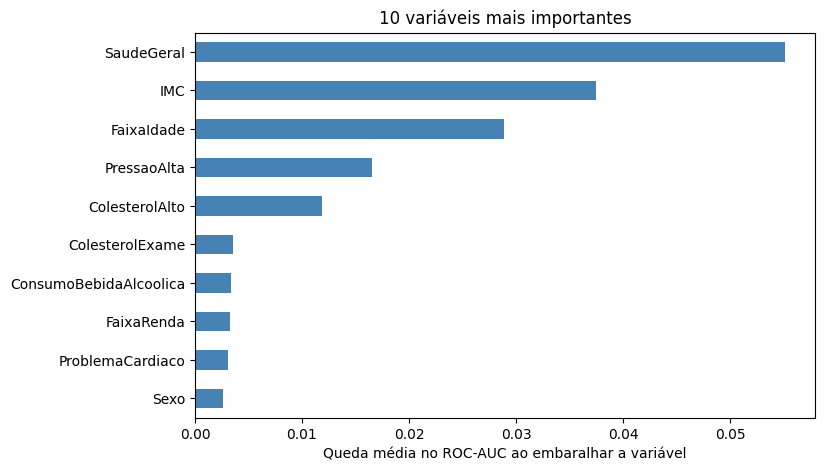

SaudeGeral                0.0552
IMC                       0.0375
FaixaIdade                0.0289
PressaoAlta               0.0166
ColesterolAlto            0.0118
ColesterolExame           0.0035
ConsumoBebidaAlcoolica    0.0033
FaixaRenda                0.0032
ProblemaCardiaco          0.0031
Sexo                      0.0026
dtype: float64

In [10]:
resultado = permutation_importance(
    melhor_modelo, X_teste, y_teste, scoring="roc_auc", n_repeats=5, random_state=SEMENTE, n_jobs=-1
)

importancias = (
    pd.Series(resultado.importances_mean, index=X_teste.columns)
    .sort_values(ascending=False)
    .head(10)
)

fig, ax = plt.subplots(figsize=(8, 5))
importancias[::-1].plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("Queda média no ROC-AUC ao embaralhar a variável")
ax.set_title("10 variáveis mais importantes")

fig.savefig(PASTA_IMAGENS / "importancia_variaveis.png", dpi=150, bbox_inches="tight")
plt.show()

importancias.round(4)


## Conclusões

- **Desempenho:** os três modelos ficaram muito próximos na validação cruzada (ROC-AUC entre 0,825 e 0,830). O Gradient Boosting foi o escolhido e obteve ROC-AUC de 0,830 no teste. A regressão logística, bem mais simples, chega perto, o que indica que a maior parte do sinal da base é aditiva e que modelos mais complexos trazem ganho pequeno.
- **Limiar de decisão:** com o limiar padrão (0,50), o Recall no teste foi de 79,9% e a Precisão de 73,3%. Com o limiar ajustado (0,35), o Recall subiu para 89,9% e a Precisão caiu para 68,1%. Para deixar passar menos casos, o modelo aceita mais falsos positivos, que na triagem significam mais pessoas encaminhadas para confirmação.
- **Variáveis mais importantes:** `SaudeGeral`, `IMC`, `FaixaIdade`, `PressaoAlta` e `ColesterolAlto`, o que é coerente com a análise exploratória dos notebooks 02 e 03.

### Limitações

- A base é balanceada (50% de cada classe), então Precisão e Acurácia **não** valem para a população real, em que o diabetes é bem menos frequente. Lá, a Precisão seria menor para o mesmo Recall.
- `Diabetes = Sim` agrupa pré-diabetes e diabetes, e os dados são autodeclarados em uma pesquisa telefônica de 2015 (BRFSS).
- A importância das variáveis mostra o que o modelo usa, não o que causa a doença. O modelo apoia a triagem e não substitui exame ou diagnóstico clínico.

### Próximos passos

- Ajustar os hiperparâmetros (busca aleatória ou em grade) e calibrar as probabilidades.
- Repetir a avaliação na base completa da mesma fonte (253.680 respostas, com classes desbalanceadas), que se aproxima mais do cenário real.
